In [1]:
#Importing important Python Libraries 
import pandas as pd
import numpy as np
from datetime import date
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#Loading Dataset
data_df = pd.read_csv("Stock Trading of Nepal Infrastructure Bank Limited.csv")
data_df = data_df.drop(columns=["Symbol", "Percent Change"])
data_df["Date"] = pd.to_datetime(data_df["Date"], dayfirst=True)
data_df["Volume"] = pd.to_numeric(data_df["Volume"].str.replace(",",""), errors = "coerce").astype(int)
data_df["Turn Over"] = pd.to_numeric(data_df["Turn Over"].str.replace(",",""), errors = "coerce").astype(float)
data_df.head()

,Date,Open,High,Low,Close,Volume,Turn Over
0,2026-10-16,249.0,250.0,246.5,246.5,64196,15954492.7
1,2026-10-15,245.1,249.5,245.1,249.0,83609,20728077.7
2,2026-10-14,243.0,247.3,242.0,247.0,52929,12971672.1
3,2026-10-13,243.0,246.9,242.4,244.3,42035,10281930.1
4,2026-10-12,245.0,250.0,244.0,244.1,71272,17550463.8


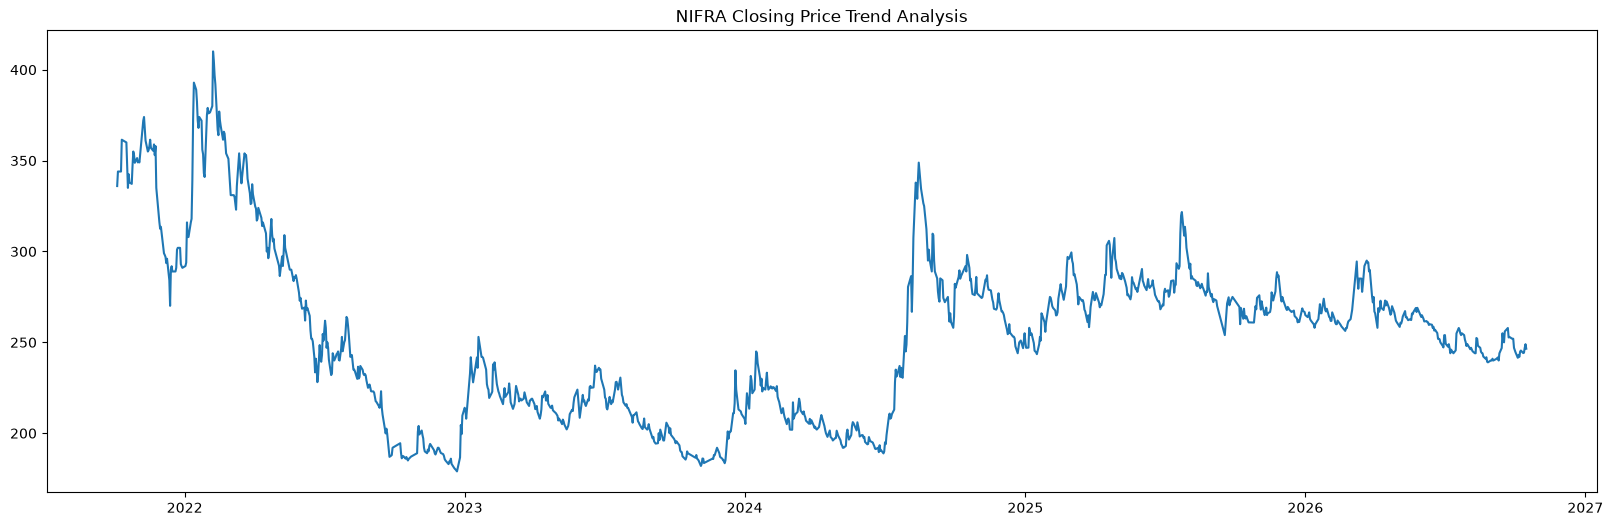

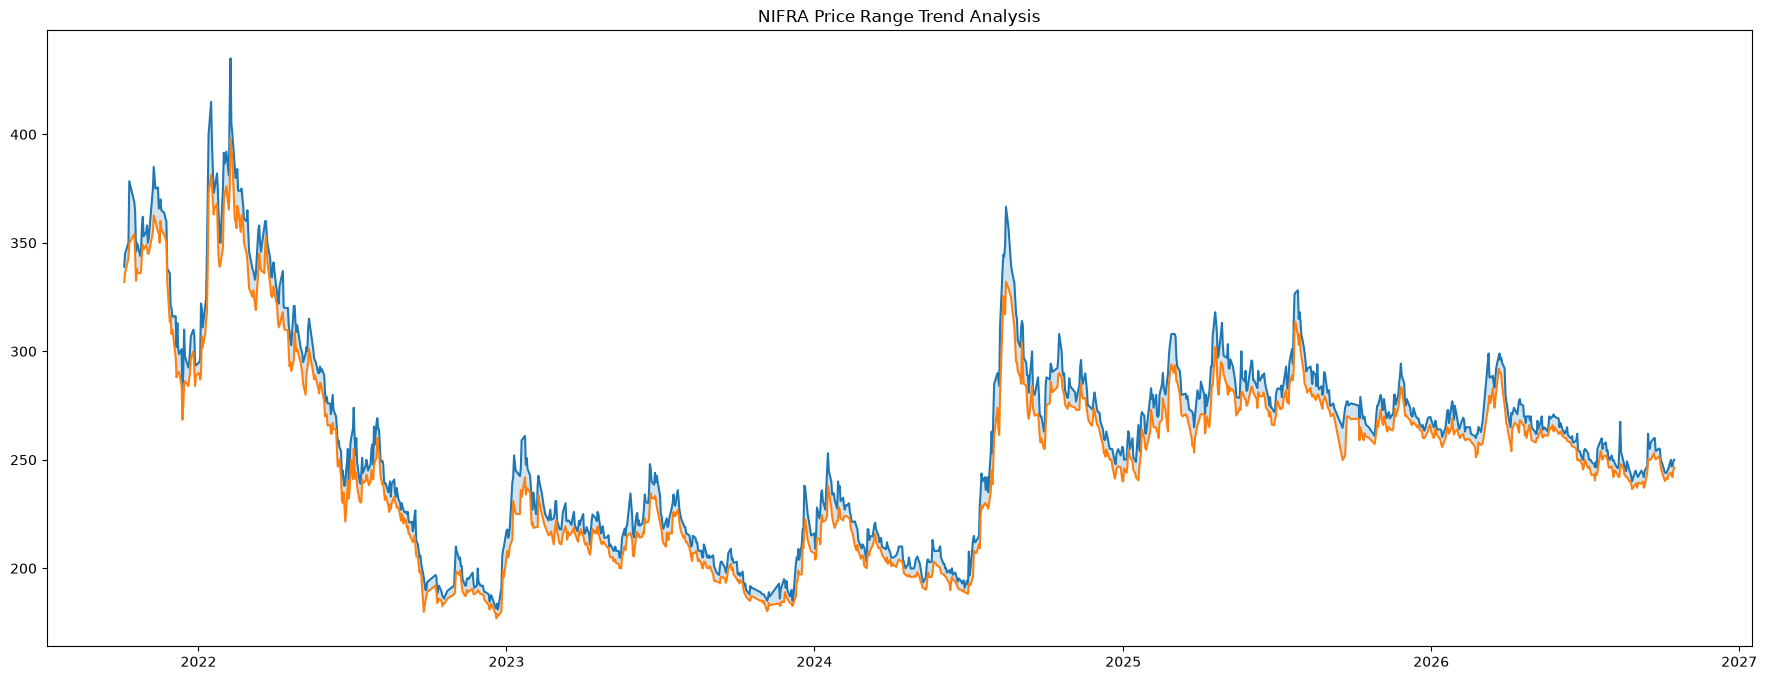

In [3]:
#Quick Look into Data
plt.figure(figsize=(20,6))
plt.title("NIFRA Closing Price Trend Analysis")
plt.plot(data_df["Date"], data_df["Close"])

plt.figure(figsize=(22,8))
plt.title("NIFRA Price Range Trend Analysis")
plt.plot(data_df["Date"], data_df["High"])
plt.plot(data_df["Date"], data_df["Low"])
plt.fill_between(
    data_df.Date,
    data_df["Low"],
    data_df["High"],
    alpha=0.2
)

In [4]:
#Price Analysis 
data_df["Daily_Avg_Price"] = (data_df.High + data_df.Low) / 2
data_df["Daily_Price_Range"] = (data_df.High - data_df.Low)
data_df["Range_Percent"] = (data_df["Daily_Price_Range"] / data_df.Close *100).round(3)
data_df[["Close", "Daily_Avg_Price", "Daily_Price_Range", "Range_Percent"]].describe()

,Close,Daily_Avg_Price,Daily_Price_Range,Range_Percent
count,1167.000000,1167.000000,1167.000000,1167.000000
mean,253.545484,254.265591,8.744893,3.378320
std,45.149784,45.330596,5.273705,1.725856
min,179.000000,179.200000,1.800000,0.686000
25%,216.100000,217.000000,5.000000,2.159500
50%,254.000000,254.000000,7.400000,2.955000
75%,278.630000,279.425000,10.900000,4.067500
max,410.100000,416.500000,38.000000,11.288000


      first   last  Annual_Return
Date                             
2021  291.0  336.0         15.464
2022  209.7  292.0         39.247
2023  210.5  214.0          1.663
2024  255.0  207.9        -18.471
2025  266.7  249.9         -6.299
2026  246.5  265.0          7.505


<Axes: title={'center': 'Annual Return (%)'}, xlabel='Date', ylabel='Cummulative Return'>

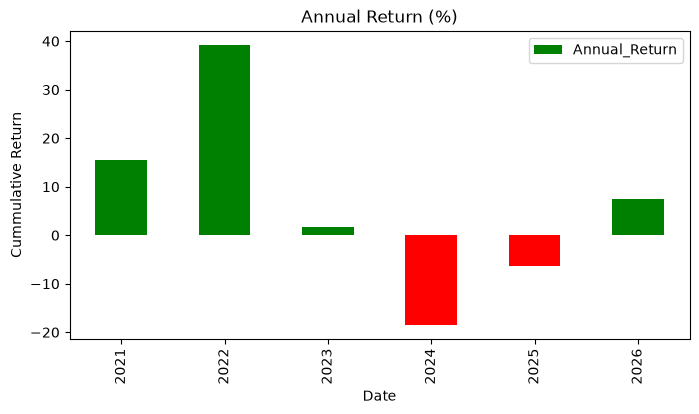

In [6]:
#Return Analysis
yearly_close = data_df.groupby( data_df["Date"].dt.year)["Close"].agg(["first", "last"])
yearly_close["Annual_Return"] = ((yearly_close["last"]/ yearly_close["first"] - 1) *100).round(3)
print(yearly_close)

colors = ["green" if val >= 0 else "red" for val in yearly_close["Annual_Return"]]
yearly_close.plot(kind="bar", figsize=(8,4), 
    title= "Annual Return (%)",
    xlabel="Date", ylabel= "Cummulative Return",
    y= "Annual_Return",
    color= colors)

Annual return gives us the exact percentage growth (or loss) of stock from the first trading day of the year to the last trading day of the year. 

<Axes: title={'center': 'Annual Average Return (%)'}, xlabel='Year', ylabel='Cummulative Return'>

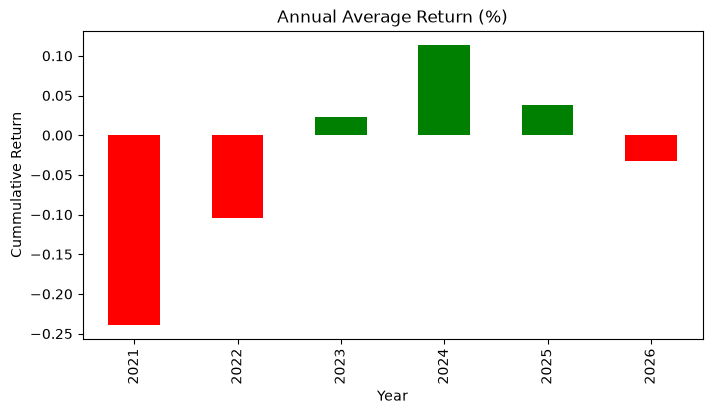

In [7]:
data_df["Return"] = (data_df["Close"][::-1].pct_change() * 100).round(3)

yearly_return = data_df.groupby(data_df["Date"].dt.to_period("Y"))["Return"].mean()
colors = ["green" if val >= 0 else "red" for val in yearly_return]
yearly_return.plot(
    kind="bar", figsize=(8,4), 
    title= "Annual Average Return (%)",
    xlabel= "Year", ylabel= "Cummulative Return",
    color= colors)

Mean of daily return gives us simple average of daily price change for the year. It treats each day as an independent event.

In [ ]:
#Risk, Volatility and Annual Analysis 

avg_return = (data_df["Return"].mean()*100).round(3)
std_deviation = (data_df["Return"].std()).round(3)
risk = (data_df["Return"].var()).round(3)
Annualized_volatility = ((
    data_df["Return"].dropna().std() / 100
) * np.sqrt(252) * 100).round(3)

print (f"Based on five years data, \nThe average rate of return from investing in the security is {avg_return}.")
print (f"The overall risk of security is {risk}")
print (f"The annualized volatility (%) is {Annualized_volatility}")
print (f"The coefficient of variance is {(std_deviation/avg_return).round(3)}")
print (f"Best daily return is {data_df["Return"].max()}")
print (f"Worst daily return is {data_df["Return"].min()}")
print ("\nAnnual interpretation of risk and return of the stock")
print (data_df.groupby(data_df["Date"].dt.year).agg(
    Avg_Close=("Close", "mean"),
    High_Price=("High", "max"),
    Low_Price=("Low", "min"),
    Max_Return=("Return", "max"),
    Min_Return=("Return", "min"),
    Return=("Return", "mean"),
    Risk=("Return", "var")
).round(3))

Based on five years data, 
The average rate of return from investing in the security is -0.329.
The overall risk of security is 4.737
The annualized volatility (%) is 34.552
The coefficient of variance is -6.617
Best daily return is 10.0
Worst daily return is -6.844

Annual interpretation of risk and return of the stock
      Avg_Close  High_Price  Low_Price  Max_Return  Min_Return  Return   Risk
Date                                                                         
2021    328.643       385.0      268.5       7.368      -6.425  -0.239  6.554
2022    265.854       435.0      176.9      10.000      -6.406  -0.104  6.370
2023    211.722       261.0      180.2       8.649      -5.021   0.023  4.291
2024    238.084       366.6      188.1       9.978      -6.844   0.114  6.395
2025    276.078       328.1      240.1       6.858      -5.929   0.038  3.566
2026    258.771       299.0      236.5       9.970      -5.105  -0.032  2.086


An annualized volatility of 34.552% indicates that the asset experiences significant price fluctuations and carries a relatively high risk profile.



In [9]:
#Price Trend Analysis
data_df["Moving_Avg_50"] = data_df["Close"][::-1].rolling(50).mean()[::-1]

data_df_moving= data_df.dropna()
data_df_moving["Moving_Avg_200"] = data_df_moving["Close"][::-1].rolling(200).mean()[::-1]

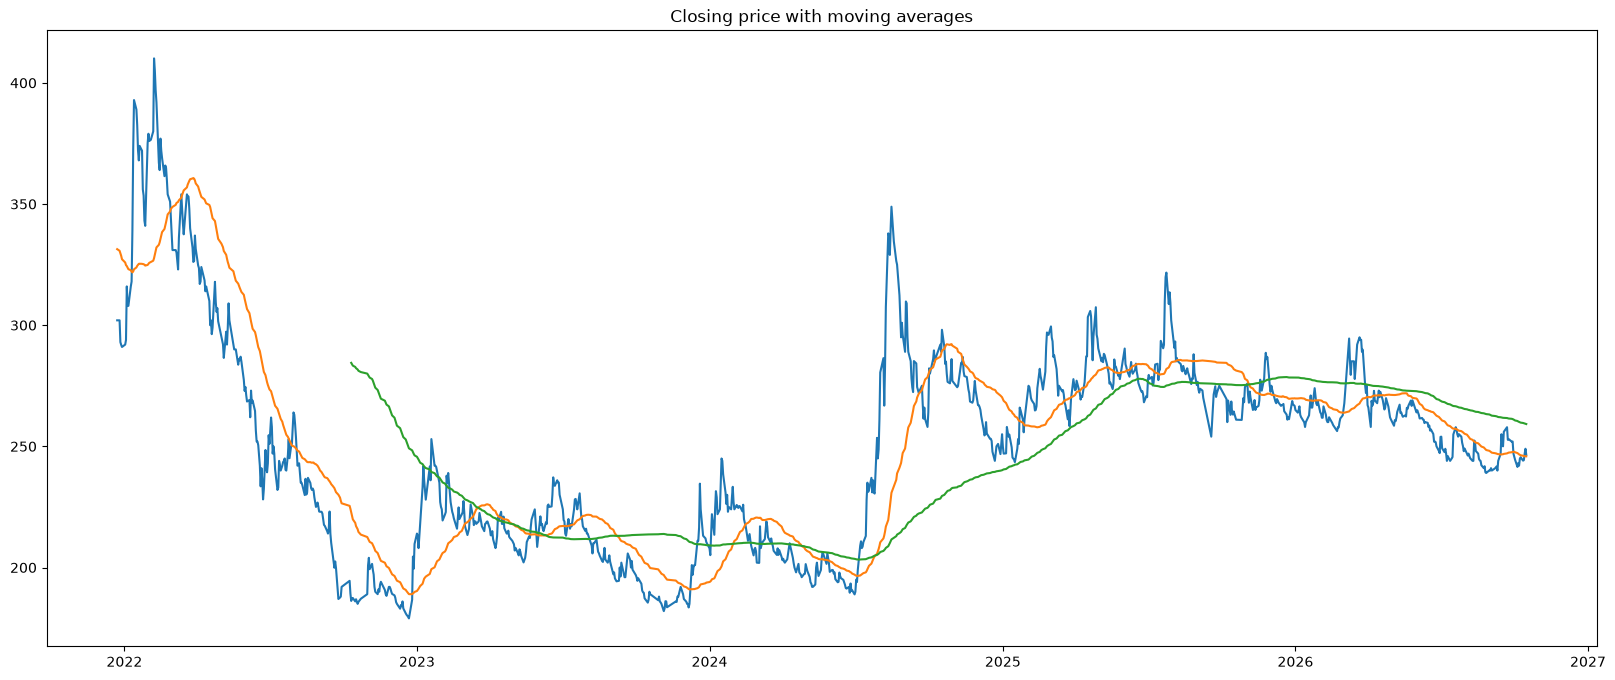

In [10]:
plt.figure(figsize=(20,8))
plt.title("Closing price with moving averages")
plt.plot(data_df_moving["Date"], data_df_moving["Close"])
plt.plot(data_df_moving["Date"], data_df_moving["Moving_Avg_50"])
plt.plot(data_df_moving["Date"], data_df_moving["Moving_Avg_200"])

* 50-Day Moving Average (approx. 10 weeks): Best for spotting intermediate-term trends and medium-term pullbacks over a multi-year window.
* 200-Day Moving Average (approx. 40 weeks): The gold standard for defining long-term market direction, structural bull/bear dividing lines, and major support or resistance across a 5-year span.
##### Interpretation
* Closing price above the moving average: price is above its recent average.
* Closing price below the moving average: price is below its recent average.

In [11]:
data_df.head()

,Date,Open,High,Low,Close,Volume,Turn Over,Daily_Avg_Price,Daily_Price_Range,Range_Percent,Return,Moving_Avg_50
0,2026-10-16,249.0,250.0,246.5,246.5,64196,15954492.7,248.25,3.5,1.420,-1.004,245.882
1,2026-10-15,245.1,249.5,245.1,249.0,83609,20728077.7,247.30,4.4,1.767,0.810,245.934
2,2026-10-14,243.0,247.3,242.0,247.0,52929,12971672.1,244.65,5.3,2.146,1.105,245.914
3,2026-10-13,243.0,246.9,242.4,244.3,42035,10281930.1,244.65,4.5,1.842,0.082,245.976
4,2026-10-12,245.0,250.0,244.0,244.1,71272,17550463.8,247.00,6.0,2.458,-0.570,246.120


### Z-score
$$ Z_t=\frac{R_t-\bar R}{s_R} $$

A common exploratory rule is to flag observations where \(|Z|>3\).

In [ ]:
#Detection of unusual movement using statistical tool (Z- Score)
data_df["Z_Score"] = (data_df["Return"] - avg_return) / std_deviation
extreme_days = data_df[data_df["Z_Score"].abs() > 3]

print(extreme_days[["Date", "Open", "Close", "Return", "Volume", "Daily_Avg_Price", "Z_Score"]])

           Date   Open   Close  Return   Volume  Daily_Avg_Price   Z_Score
149  2026-03-09  273.1  294.50   9.970    13492           283.80  4.730822
245  2025-09-21  254.0  271.42   6.858   248763           262.95  3.301332
465  2024-10-01  264.1  282.20   6.853   345145           274.00  3.299035
484  2024-09-02  285.0  309.80   7.197   535600           298.00  3.457051
497  2024-08-11  313.6  337.90   9.886  2091470           325.80  4.692237
498  2024-08-08  285.0  307.50   8.657  3037821           295.65  4.127699
502  2024-08-01  266.2  280.50   7.471  1494471           272.95  3.582912
506  2024-07-28  235.1  253.50   9.978   992125           244.30  4.734497
515  2024-07-15  216.0  228.00   7.042   984199           219.10  3.385852
600  2024-03-04  205.9  217.00   7.479    21529           211.95  3.586587
633  2024-01-16  225.0  245.00   9.375   979409           234.55  4.457510
648  2023-12-20  220.8  234.60   8.360   761161           227.55  3.991272
656  2023-12-10  187.0  2